# Retail Store Performance & Trend Analysis

**Internship:** Syntecxhub – Data Science Internship (Week 2)

## Project Overview
This project analyzes retail store sales data to identify trends over time, compare product categories, and understand regional performance using data visualization.

## Objectives
- Analyze monthly and quarterly sales trends.
- Compare sales across product categories.
- Understand category-wise sales distribution.
- Analyze regional sales performance.
- Create visualizations and derive insights from sales data.

## Tools Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import pandas as pd
import numpy as np

np.random.seed(101)

dates = pd.date_range("2023-01-01", "2024-12-31", freq="D")

products = {
    "Electronics": {"Tablet": 18000, "Camera": 32000, "Speaker": 4000, "Mouse": 800, "Monitor": 12000},
    "Fashion": {"T-Shirt": 700, "Jeans": 1600, "Sneakers": 2800, "Dress": 2200, "Hoodie": 1800},
    "Home & Kitchen": {"Mixer": 3500, "Cooker": 2200, "Lamp": 1200, "Pan": 900, "Blender": 2500},
    "Beauty": {"Perfume": 1500, "Face Cream": 600, "Shampoo": 350, "Serum": 900, "Sunscreen": 500},
    "Sports": {"Yoga Mat": 1200, "Dumbbells": 2500, "Football": 900, "Skipping Rope": 300, "Gym Bag": 1800}
}

region_cities = {
    "North": ["Delhi", "Jaipur", "Lucknow", "Amritsar"],
    "South": ["Chennai", "Bengaluru", "Hyderabad", "Kochi"],
    "East": ["Kolkata", "Patna", "Ranchi", "Guwahati"],
    "West": ["Mumbai", "Pune", "Surat", "Ahmedabad"]
}

categories = list(products.keys())
regions = list(region_cities.keys())
n = 5000

sales_dates = np.random.choice(dates, n)
sales_categories = np.random.choice(categories, n)
sales_regions = np.random.choice(regions, n)
quantities = np.random.randint(1, 11, n)
discounts = np.random.choice([0, 5, 10, 15, 20], n)

selected_products = []
unit_prices = []
cities = []

for i in range(n):
    category = sales_categories[i]
    product = np.random.choice(list(products[category].keys()))
    price = products[category][product]

    region = sales_regions[i]
    city = np.random.choice(region_cities[region])

    selected_products.append(product)
    unit_prices.append(price)
    cities.append(city)

df = pd.DataFrame({
    "Order_ID": range(20001, 20001+n),
    "Date": sales_dates,
    "Category": sales_categories,
    "Product": selected_products,
    "Region": sales_regions,
    "City": cities,
    "Quantity": quantities,
    "Unit_Price": unit_prices,
    "Discount_Percent": discounts
})

df["Gross_Sales"] = df["Quantity"] * df["Unit_Price"]
df["Discount_Amount"] = df["Gross_Sales"] * df["Discount_Percent"] / 100
df["Sales"] = df["Gross_Sales"] - df["Discount_Amount"]

cost_percentages = {
    "Electronics": 0.75,
    "Fashion": 0.55,
    "Home & Kitchen": 0.65,
    "Beauty": 0.50,
    "Sports": 0.60
}

df["Estimated_Cost"] = df["Gross_Sales"] * df["Category"].map(cost_percentages)
df["Profit"] = df["Sales"] - df["Estimated_Cost"]

df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

print("Retail sales dataset created successfully!")
print("Total records:", len(df))

Retail sales dataset created successfully!
Total records: 5000


In [3]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (5000, 14)

Column Names:
['Order_ID', 'Date', 'Category', 'Product', 'Region', 'City', 'Quantity', 'Unit_Price', 'Discount_Percent', 'Gross_Sales', 'Discount_Amount', 'Sales', 'Estimated_Cost', 'Profit']

First 5 Rows:


,Order_ID,Date,Category,Product,Region,City,Quantity,Unit_Price,Discount_Percent,Gross_Sales,Discount_Amount,Sales,Estimated_Cost,Profit
0,23762,2023-01-01,Fashion,Dress,East,Kolkata,7,2200,20,15400,3080.0,12320.0,8470.0,3850.0
1,23908,2023-01-01,Home & Kitchen,Mixer,East,Guwahati,6,3500,20,21000,4200.0,16800.0,13650.0,3150.0
2,21913,2023-01-01,Fashion,Hoodie,South,Kochi,10,1800,15,18000,2700.0,15300.0,9900.0,5400.0
3,22556,2023-01-02,Electronics,Speaker,West,Ahmedabad,7,4000,15,28000,4200.0,23800.0,21000.0,2800.0
4,22442,2023-01-02,Fashion,Sneakers,East,Ranchi,7,2800,5,19600,980.0,18620.0,10780.0,7840.0



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Order_ID          5000 non-null   int64         
 1   Date              5000 non-null   datetime64[us]
 2   Category          5000 non-null   str           
 3   Product           5000 non-null   str           
 4   Region            5000 non-null   str           
 5   City              5000 non-null   str           
 6   Quantity          5000 non-null   int32         
 7   Unit_Price        5000 non-null   int64         
 8   Discount_Percent  5000 non-null   int64         
 9   Gross_Sales       5000 non-null   int64         
 10  Discount_Amount   5000 non-null   float64       
 11  Sales             5000 non-null   float64       
 12  Estimated_Cost    5000 non-null   float64       
 13  Profit            5000 non-null   float64       
dtypes: datetime64

,Order_ID,Date,Quantity,Unit_Price,Discount_Percent,Gross_Sales,Discount_Amount,Sales,Estimated_Cost,Profit
count,5000.000000,5000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,22500.500000,2024-01-01 12:40:19.200000,5.471800,3845.870000,10.160000,20946.710000,2178.074500,18768.635500,14667.263000,4101.372500
min,20001.000000,2023-01-01 00:00:00,1.000000,300.000000,0.000000,300.000000,0.000000,240.000000,175.000000,40.000000
25%,21250.750000,2023-07-07 00:00:00,3.000000,900.000000,5.000000,3200.000000,120.000000,2880.000000,1760.000000,945.000000
50%,22500.500000,2024-01-02 00:00:00,5.000000,1600.000000,10.000000,7200.000000,540.000000,6480.000000,4360.000000,2100.000000
75%,23750.250000,2024-06-28 00:00:00,8.000000,2500.000000,15.000000,16200.000000,1600.000000,14400.000000,9720.000000,4320.000000
max,25000.000000,2024-12-31 00:00:00,10.000000,32000.000000,20.000000,320000.000000,64000.000000,320000.000000,240000.000000,80000.000000
std,1443.520003,NaN,2.850128,6891.729219,7.069964,43261.916536,5769.098369,38745.810594,32658.213283,6938.244814


In [4]:
print("Total Sales:", round(df["Sales"].sum(), 2))
print("Total Profit:", round(df["Profit"].sum(), 2))
print("Total Orders:", df["Order_ID"].nunique())
print("Total Units Sold:", df["Quantity"].sum())
print("Average Order Sales:", round(df["Sales"].mean(), 2))
print("Highest Sale:", round(df["Sales"].max(), 2))
print("Lowest Sale:", round(df["Sales"].min(), 2))

print("\nCategory-wise Sales:")
display(df.groupby("Category")["Sales"].sum().sort_values(ascending=False))

print("\nRegion-wise Sales:")
display(df.groupby("Region")["Sales"].sum().sort_values(ascending=False))

Total Sales: 93843177.5
Total Profit: 20506862.5
Total Orders: 5000
Total Units Sold: 27359
Average Order Sales: 18768.64
Highest Sale: 320000.0
Lowest Sale: 240.0

Category-wise Sales:


Category
Electronics       64706620.0
Home & Kitchen    10081280.0
Fashion            8659320.0
Sports             6535415.0
Beauty             3860542.5
Name: Sales, dtype: float64


Region-wise Sales:


Region
South    24170072.5
North    23948820.0
West     23297782.5
East     22426502.5
Name: Sales, dtype: float64

In [5]:
df["Month"] = df["Date"].dt.to_period("M")

monthly_sales = df.groupby("Month").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order_ID", "count"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

monthly_sales["Month"] = monthly_sales["Month"].astype(str)

display(monthly_sales.head(12))

,Month,Total_Sales,Total_Profit,Total_Orders,Total_Quantity
0,2023-01,3201185.0,700260.0,207,1137
1,2023-02,4840497.5,1058907.5,190,1067
2,2023-03,3127690.0,714870.0,205,1128
3,2023-04,3914817.5,826832.5,208,1153
4,2023-05,4070215.0,898330.0,203,1111
5,2023-06,3520352.5,748577.5,198,1136
6,2023-07,4353782.5,827162.5,216,1147
7,2023-08,4655000.0,941495.0,194,1112
8,2023-09,3427125.0,778080.0,210,1058
9,2023-10,3792275.0,845300.0,237,1270


In [6]:
df["Quarter"] = df["Date"].dt.to_period("Q")

quarterly_sales = df.groupby("Quarter").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order_ID", "count"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

quarterly_sales["Quarter"] = quarterly_sales["Quarter"].astype(str)

display(quarterly_sales)

,Quarter,Total_Sales,Total_Profit,Total_Orders,Total_Quantity
0,2023Q1,11169372.5,2474037.5,602,3332
1,2023Q2,11505385.0,2473740.0,609,3400
2,2023Q3,12435907.5,2546737.5,620,3317
3,2023Q4,11665127.5,2579577.5,663,3653
4,2024Q1,11715107.5,2785742.5,669,3662
5,2024Q2,11987467.5,2723642.5,601,3289
6,2024Q3,10221472.5,2271717.5,597,3259
7,2024Q4,13143337.5,2651667.5,639,3447


In [7]:
category_summary = df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order_ID", "count"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

category_summary = category_summary.sort_values(
    "Total_Sales", ascending=False
)

display(category_summary)

,Category,Total_Sales,Total_Profit,Total_Orders,Total_Quantity
1,Electronics,64706620.0,10458220.0,983,5351
3,Home & Kitchen,10081280.0,2810835.0,1005,5391
2,Fashion,8659320.0,3349785.0,970,5394
4,Sports,6535415.0,2177855.0,995,5429
0,Beauty,3860542.5,1710167.5,1047,5794


In [8]:
region_summary = df.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order_ID", "count"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

region_summary = region_summary.sort_values(
    "Total_Sales", ascending=False
)

display(region_summary)

,Region,Total_Sales,Total_Profit,Total_Orders,Total_Quantity
2,South,24170072.5,5382742.5,1263,6873
1,North,23948820.0,5293560.0,1244,6918
3,West,23297782.5,5014102.5,1279,7044
0,East,22426502.5,4816457.5,1214,6524


In [9]:
product_summary = df.groupby(["Category", "Product"]).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order_ID", "count"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

product_summary = product_summary.sort_values(
    "Total_Sales", ascending=False
)

display(product_summary.head(15))

,Category,Product,Total_Sales,Total_Profit,Total_Orders,Total_Quantity
5,Electronics,Camera,30171200.0,4755200.0,198,1059
9,Electronics,Tablet,17766900.0,2916900.0,196,1100
6,Electronics,Monitor,12487200.0,2101200.0,209,1154
8,Electronics,Speaker,3532200.0,565200.0,186,989
18,Home & Kitchen,Mixer,3525900.0,982450.0,210,1118
15,Home & Kitchen,Blender,2478500.0,700750.0,210,1094
13,Fashion,Sneakers,2478000.0,962640.0,176,984
20,Sports,Dumbbells,2341625.0,786125.0,187,1037
10,Fashion,Dress,2227390.0,856460.0,199,1133
16,Home & Kitchen,Cooker,2009370.0,549340.0,201,1021


In [10]:
city_summary = df.groupby(["Region", "City"]).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order_ID", "count")
).reset_index()

city_summary = city_summary.sort_values(
    "Total_Sales", ascending=False
)

display(city_summary.head(15))

,Region,City,Total_Sales,Total_Profit,Total_Orders
10,South,Hyderabad,7019920.0,1561750.0,343
4,North,Amritsar,6434992.5,1416822.5,316
6,North,Jaipur,6320780.0,1411980.0,327
8,South,Bengaluru,6199825.0,1368345.0,300
3,East,Ranchi,6193470.0,1369275.0,317
14,West,Pune,6063550.0,1334825.0,311
13,West,Mumbai,5863975.0,1380215.0,355
11,South,Kochi,5859235.0,1308165.0,306
15,West,Surat,5817527.5,1155067.5,293
7,North,Lucknow,5816702.5,1220462.5,310


In [11]:
df.to_csv("retail_sales_dataset.csv", index=False)
monthly_sales.to_csv("monthly_sales_summary.csv", index=False)
quarterly_sales.to_csv("quarterly_sales_summary.csv", index=False)
category_summary.to_csv("category_sales_summary.csv", index=False)
region_summary.to_csv("region_sales_summary.csv", index=False)
product_summary.to_csv("product_sales_summary.csv", index=False)
city_summary.to_csv("city_sales_summary.csv", index=False)

print("All CSV files saved successfully!")

All CSV files saved successfully!


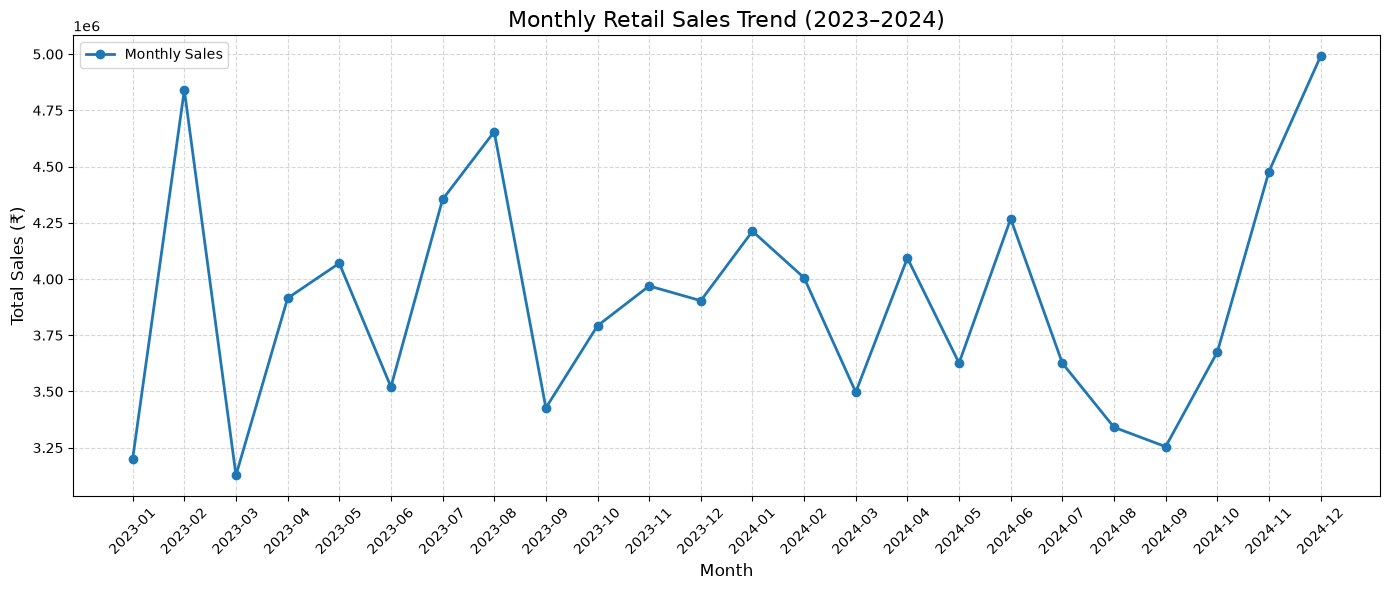

In [12]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["Month"],
    monthly_sales["Total_Sales"],
    marker="o",
    linewidth=2,
    label="Monthly Sales"
)

plt.title("Monthly Retail Sales Trend (2023–2024)", fontsize=16)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Total Sales (₹)", fontsize=12)

plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()

plt.savefig("monthly_sales_line_chart.png", dpi=300)
plt.show()

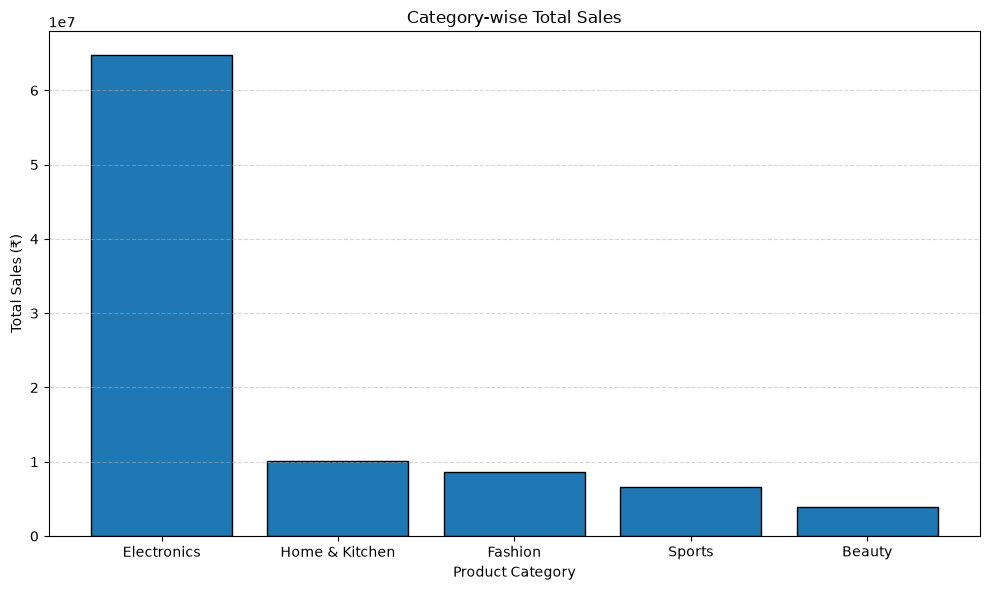

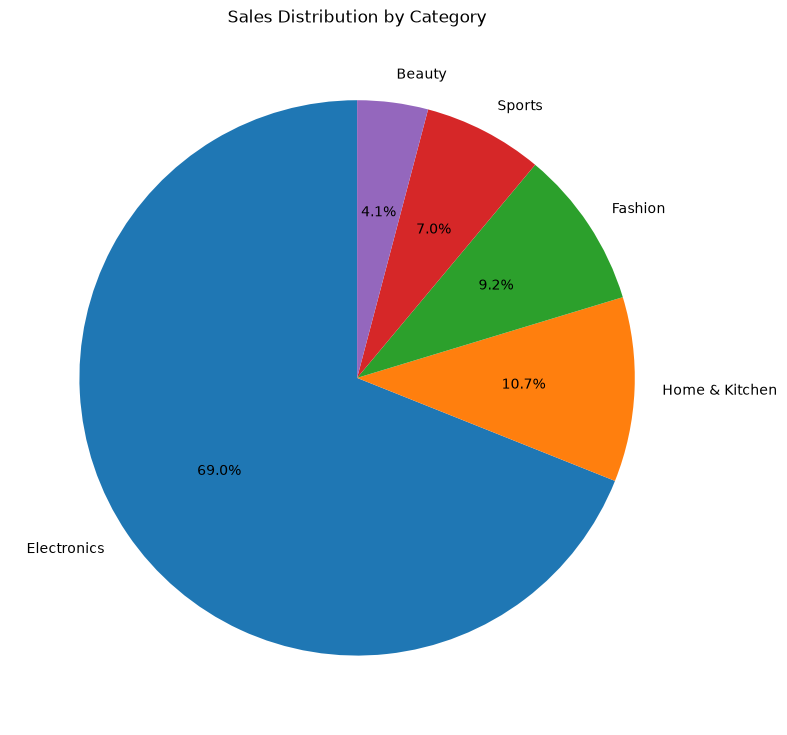

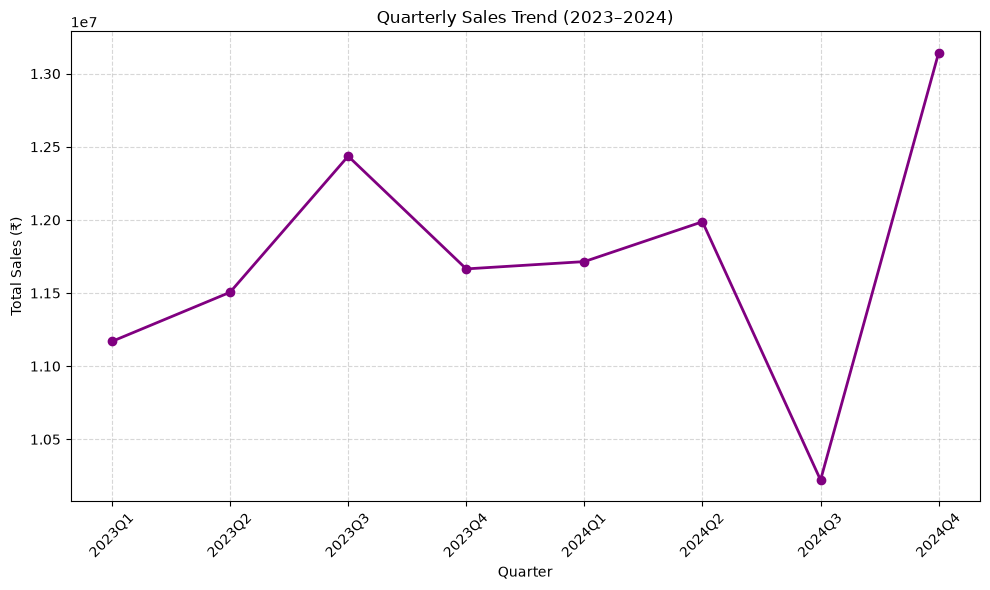

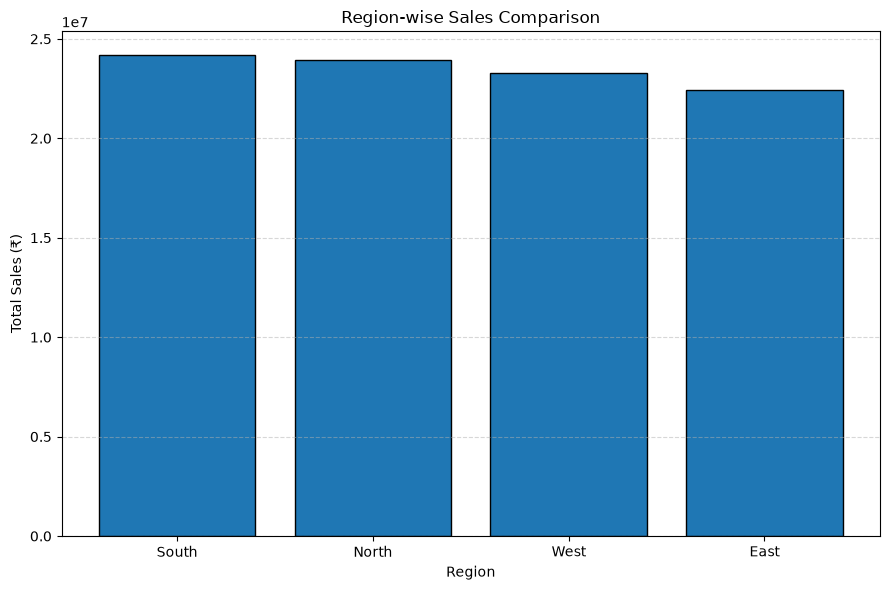

All remaining charts created and saved successfully!


In [13]:
# 1. Category-wise Sales Bar Chart
plt.figure(figsize=(10, 6))
plt.bar(category_summary["Category"], category_summary["Total_Sales"], edgecolor="black")
plt.title("Category-wise Total Sales")
plt.xlabel("Product Category")
plt.ylabel("Total Sales (₹)")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("category_sales_bar_chart.png", dpi=300)
plt.show()


# 2. Category Sales Pie Chart
plt.figure(figsize=(8, 8))
plt.pie(
    category_summary["Total_Sales"],
    labels=category_summary["Category"],
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Sales Distribution by Category")
plt.tight_layout()
plt.savefig("category_sales_pie_chart.png", dpi=300)
plt.show()


# 3. Quarterly Sales Line Chart
plt.figure(figsize=(10, 6))
plt.plot(
    quarterly_sales["Quarter"],
    quarterly_sales["Total_Sales"],
    marker="o",
    color="purple",
    linewidth=2
)
plt.title("Quarterly Sales Trend (2023–2024)")
plt.xlabel("Quarter")
plt.ylabel("Total Sales (₹)")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("quarterly_sales_chart.png", dpi=300)
plt.show()


# 4. Region-wise Sales Bar Chart
plt.figure(figsize=(9, 6))
plt.bar(region_summary["Region"], region_summary["Total_Sales"], edgecolor="black")
plt.title("Region-wise Sales Comparison")
plt.xlabel("Region")
plt.ylabel("Total Sales (₹)")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("region_sales_bar_chart.png", dpi=300)
plt.show()


print("All remaining charts created and saved successfully!")

In [14]:
best_category = category_summary.loc[
    category_summary["Total_Sales"].idxmax(), "Category"
]

best_region = region_summary.loc[
    region_summary["Total_Sales"].idxmax(), "Region"
]

summary_text = f"""
RETAIL STORE PERFORMANCE & TREND ANALYSIS
PROJECT SUMMARY
======================================

Total Orders: {df["Order_ID"].nunique():,}
Total Units Sold: {df["Quantity"].sum():,}
Total Sales: Rs. {df["Sales"].sum():,.2f}
Total Profit: Rs. {df["Profit"].sum():,.2f}
Average Order Sales: Rs. {df["Sales"].mean():,.2f}

Best Performing Category: {best_category}
Best Performing Region: {best_region}

CHARTS CREATED:
1. Monthly Sales Line Chart
2. Category Sales Bar Chart
3. Category Sales Pie Chart
4. Quarterly Sales Chart
5. Region-wise Sales Bar Chart

CHART SELECTION:
Line charts were used to display sales trends over time.
Bar charts were used to compare sales between categories and regions.
Pie charts were used to show the contribution of each category
to total sales.

FORMATTING:
Titles, axis labels, gridlines, percentage labels and suitable
figure sizes were used to improve chart readability.

CONCLUSION:
This project analyzes retail sales data to identify trends,
compare categories, and understand regional performance using
Python data analysis and visualization.
"""

with open("project_summary.txt", "w", encoding="utf-8") as file:
    file.write(summary_text)

print(summary_text)
print("Project summary saved successfully!")


RETAIL STORE PERFORMANCE & TREND ANALYSIS
PROJECT SUMMARY

Total Orders: 5,000
Total Units Sold: 27,359
Total Sales: Rs. 93,843,177.50
Total Profit: Rs. 20,506,862.50
Average Order Sales: Rs. 18,768.64

Best Performing Category: Electronics
Best Performing Region: South

CHARTS CREATED:
1. Monthly Sales Line Chart
2. Category Sales Bar Chart
3. Category Sales Pie Chart
4. Quarterly Sales Chart
5. Region-wise Sales Bar Chart

CHART SELECTION:
Line charts were used to display sales trends over time.
Bar charts were used to compare sales between categories and regions.
Pie charts were used to show the contribution of each category
to total sales.

FORMATTING:
Titles, axis labels, gridlines, percentage labels and suitable
figure sizes were used to improve chart readability.

CONCLUSION:
This project analyzes retail sales data to identify trends,
compare categories, and understand regional performance using
Python data analysis and visualization.

Project summary saved successfully!


In [15]:
readme_content = """
# Retail Store Performance & Trend Analysis

## Internship
Syntecxhub - Data Science Internship (Week 2)

## Project Overview
This project analyzes retail store sales data using time-series
and category-based visualizations to understand trends, sales
performance, product categories, and regional performance.

## Objectives
- Analyze monthly and quarterly sales trends.
- Compare product categories.
- Understand category-wise sales distribution.
- Analyze region-wise sales performance.
- Generate insights using charts.

## Dataset
A synthetic dataset containing 5,000 sales records with:
- Order ID and Date
- Category and Product
- Region and City
- Quantity and Unit Price
- Discounts
- Sales and Estimated Profit

## Tools & Libraries
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

## Visualizations
1. Monthly Sales Line Chart
2. Category-wise Sales Bar Chart
3. Category Sales Pie Chart
4. Quarterly Sales Trend Chart
5. Region-wise Sales Bar Chart

## Project Files
- Jupyter Notebook
- Retail Sales Dataset CSV
- Summary CSV files
- Chart PNG files
- Project Summary text file

## Conclusion
The project uses data analysis and visualization to understand
retail sales patterns, compare categories, and identify regional
performance.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content)

import os

print("README created successfully!")
print("\nAll project files:")
for file in sorted(os.listdir()):
    if file.endswith((".csv", ".png", ".txt", ".md", ".ipynb")):
        print(file)

README created successfully!

All project files:
README.md
Retail_Store_Performance_Analysis.ipynb
category_sales_bar_chart.png
category_sales_pie_chart.png
category_sales_summary.csv
city_sales_summary.csv
monthly_sales_line_chart.png
monthly_sales_summary.csv
product_sales_summary.csv
project_summary.txt
quarterly_sales_chart.png
quarterly_sales_summary.csv
region_sales_bar_chart.png
region_sales_summary.csv
retail_sales_dataset.csv
